## CNN time series classification - Gold Price Time-Series Dataset

<li>Dataset Name: Gold Price Time-Series Dataset</li>
<li>Dataset Link: <a href="https://www.kaggle.com/datasets/boiniabhiram/gold-price-time-series-dataset" target="_blank">Gold Price Time-Series Dataset (Kaggle)</a></li>

In [2]:
# Imports
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# if your Jupyter kernel crashes during this code, use this setting
# import os
# os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [3]:
# Load the Dataset
df = pd.read_csv("gold_price_data.csv")

In [4]:
df.head()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,2008-01-02,1447.160034,84.860001,78.470001,15.180,1.471692
1,2008-01-03,1447.160034,85.570000,78.370003,15.285,1.474491
2,2008-01-04,1411.630005,85.129997,77.309998,15.167,1.475492
3,2008-01-07,1416.180054,84.769997,75.500000,15.053,1.468299
4,2008-01-08,1390.189941,86.779999,76.059998,15.590,1.557099


In [5]:
df.describe()

,SPX,GLD,USO,SLV,EUR/USD
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1655.401978,122.677732,31.911996,20.146645,1.284604
std,516.006509,23.255837,19.349284,7.056861,0.131411
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1246.559967,109.416305,14.557500,15.580000,1.175858
50%,1562.480214,120.650002,33.805000,17.440001,1.302329
75%,2066.734924,133.695060,37.959999,23.607495,1.371103
max,2872.870117,184.589996,117.480003,47.259998,1.598798


In [6]:
# this data format is not suitable yet for CNN time series classification
# because each point is separate in the dataset

# we have to process the data into smaller chunks => for example
# chunks of 50 points at a time

# let's select GLD (gold) and SLV (silver) as our variables
# in other words, we try to detect if any given signal is GLD or SLV
df = df.drop(['SPX', 'USO', 'EUR/USD'], axis=1)

In [7]:
df.head()

,Date,GLD,SLV
0,2008-01-02,84.860001,15.180
1,2008-01-03,85.570000,15.285
2,2008-01-04,85.129997,15.167
3,2008-01-07,84.769997,15.053
4,2008-01-08,86.779999,15.590


In [8]:
# we'll use a sequence number instead of a timestamp
# starting from 1 until the final row
df = df.reset_index()
df['sequence'] = df.index + 1
df = df.drop(['Date', 'index'], axis=1)

In [9]:
df.head()

,GLD,SLV,sequence
0,84.860001,15.180,1
1,85.570000,15.285,2
2,85.129997,15.167,3
3,84.769997,15.053,4
4,86.779999,15.590,5


In [10]:
df.tail()

,GLD,SLV,sequence
2495,123.617723,24.436414,2496
2496,83.882655,24.675277,2497
2497,94.192949,21.676936,2498
2498,112.048514,19.811873,2499
2499,137.921134,30.557457,2500


Split the DataFrame into timesteps
ALTERNATIVE 1: Windowing (use only if you don't have much data)

See CNN-materials for visualization on what windowing does!

In [11]:
from numpy.lib.stride_tricks import sliding_window_view

timestep_size = 50

# separate the output variables
gld = df['GLD'].values
slv = df['SLV'].values

# generate timestep windows for each signal
gld_windows = sliding_window_view(gld, window_shape=timestep_size)
slv_windows = sliding_window_view(slv, window_shape=timestep_size)

# combine into X and y
# use vstack to combine gold and silver back together
X = np.vstack((gld_windows, slv_windows))

# generate zeroes and ones for the output categories
# 0 = GLD
# 1 = SLV
y = np.array([0] * len(gld_windows) + [1] * len(slv_windows))

print("X:", X.shape)
print("y:", y.shape)

X: (4902, 50)
y: (4902,)


ALTERNATIVE 2: separate timesteps (use only if you have a lot of data)

In [12]:
# from numpy.lib.stride_tricks import sliding_window_view

# timestep_size = 50

# # separate the output variables
# gld = df['GLD'].values
# slv = df['SLV'].values

# # for separate timesteps, add [::timestep_size] for each dataset
# # this results into a set of timesteps with no overlap! (in sequence)
# # RULE OF THUMB! If you have lots of data => use separate timesteps to avoid redundancy in data
# # If you lack data, use sliding window instead (to get more data, but also having redundancy introduced)
# # using separate time steps will also discard any extra data that doesn't fill the final timestep
# gld_windows = sliding_window_view(gld, window_shape=timestep_size)[::timestep_size]
# slv_windows = sliding_window_view(slv, window_shape=timestep_size)[::timestep_size]

# # combine into X and y
# X = np.vstack((gld_windows, slv_windows))

# # 0 = GLD
# # 1 = SLV
# y = np.array([0] * len(gld_windows) + [1] * len(slv_windows))

# print("X:", X.shape)
# print("y:", y.shape)

Shuffle the data

In [13]:
from sklearn.utils import shuffle

# shuffle the data
X, y = shuffle(X, y, random_state=42)

Visualize some test signals

Change the signal index in order to see a different subsignal.

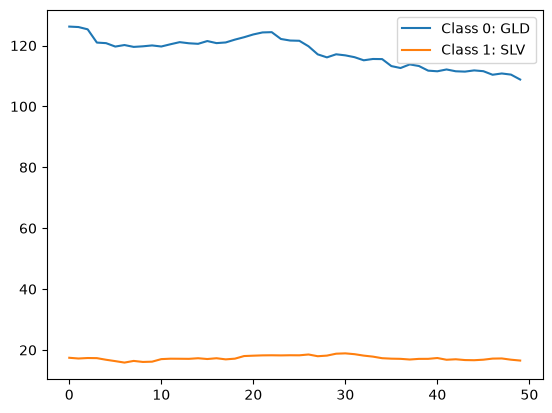

In [14]:
test_signal_index = 2

c_x_train = X[y == 0]
plt.plot(c_x_train[test_signal_index], label="Class 0: GLD")

c_x_train = X[y == 1]
plt.plot(c_x_train[test_signal_index], label="Class 1: SLV")
plt.legend()

Finally we can do the train/test -split

In [15]:
# define the cutoff point
# usually it's easiest just to do the splitting with a splitter index
# when it comes to CNN time series classification datasets
train_size = 0.7
splitter = int(len(X) * train_size)

# split to train/test
x_train = X[0:splitter]
x_test = X[splitter:]
y_train = y[0:splitter]
y_test = y[splitter:]

Important in CNN => scale the values
MinMaxScaler is enough!

In [16]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [17]:
print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

3431
1471
3431
1471


In [18]:
# convert the data into the required CNN-format
# usually the easiest approach is to modify
# your own dataset to follow the data format used by another example
# ALSO: luckily, generative AIs are quite helpful nowadays in helping
# to reshape your data into correct format
x_train = x_train.reshape((x_train.shape[0], x_train.shape[1], 1))
x_test = x_test.reshape((x_test.shape[0], x_test.shape[1], 1))

In [19]:
# compare this to a known example
# where it works to check that you have
# the correct data format (e.g. FordA)
x_train

array([[[0.08861586],
        [0.07729888],
        [0.01580478],
        ...,
        [0.07527   ],
        [0.09917183],
        [0.09673538]],

       [[0.11465802],
        [0.11431661],
        [0.11582879],
        ...,
        [0.10669171],
        [0.10858949],
        [0.10953682]],

       [[0.90622513],
        [0.9055992 ],
        [0.91065792],
        ...,
        [0.87077506],
        [0.87601271],
        [0.86343462]],

       ...,

       [[0.04000228],
        [0.0406282 ],
        [0.04228669],
        ...,
        [0.0381245 ],
        [0.03895432],
        [0.03846592]],

       [[0.15187209],
        [0.157164  ],
        [0.15667911],
        ...,
        [0.14236941],
        [0.14834817],
        [0.14811654]],

       [[0.6010015 ],
        [0.60242405],
        [0.6083884 ],
        ...,
        [0.62950953],
        [0.63941398],
        [0.63599639]]])

Define a CNN -time series classification network for our data

In [20]:
class_names = np.array(['GLD', 'SLV'])
num_classes = len(class_names)
classes = [0, 1]

def make_model(input_shape):
    model = keras.Sequential(
        [
            # input layer
            keras.layers.Input(input_shape),

            # convolutional layer 1 (we usually have 1-3 convolutional layers
            # depending how much and how complex the data is) -> "model capacity / decision space"
            keras.layers.Conv1D(filters=64, kernel_size=3, padding="same"),
            keras.layers.BatchNormalization(),
            keras.layers.ReLU(),

            # pooling + flatten (adapter from convolutional to dense)
            # flattening is done only once after the final convolutional layer 
            # and before the Dense-network
            keras.layers.GlobalAveragePooling1D(),
            keras.layers.Flatten(),

            # neural network Dense-tail
            keras.layers.Dense(64, activation="relu"),

            # output layer
            keras.layers.Dense(num_classes, activation="softmax")
        ]
    )

    return model


model = make_model(input_shape=x_train.shape[1:])

# pip install pydot -> restart Jupyter kernel after this
# keras.utils.plot_model(model, show_shapes=True)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 50, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,802 (18.76 KB)

 Trainable params: 4,674 (18.26 KB)

 Non-trainable params: 128 (512.00 B)

Train the model

In [21]:
epochs = 500
batch_size = 32

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_model_gold.keras", save_best_only=True, monitor="val_loss"
    ),
]
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)
history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    callbacks=callbacks,
    validation_split=0.2,
    verbose=1,
)

Epoch 1/500
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1058 - sparse_categorical_accuracy: 0.9800 - val_loss: 0.3900 - val_sparse_categorical_accuracy: 0.9272
Epoch 2/500
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0142 - sparse_categorical_accuracy: 0.9974 - val_loss: 0.2034 - val_sparse_categorical_accuracy: 1.0000
Epoch 3/500
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0077 - sparse_categorical_accuracy: 0.9978 - val_loss: 0.0892 - val_sparse_categorical_accuracy: 1.0000
Epoch 4/500
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0093 - sparse_categorical_accuracy: 0.9964 - val_loss: 0.0379 - val_sparse_categorical_accuracy: 1.0000
Epoch 5/500
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0033 - sparse_categorical_accuracy: 0.9993 - val_loss: 0.0064 - val_sparse_categorical_accuracy: 1.0000
Epoch 6/500
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0031 - sparse_categorical_accuracy: 0.9985 - val_loss: 0.0020 - val_sparse_categorical_accuracy: 1.0000
Epoch 7/50

Metrics and plots

<Axes: >

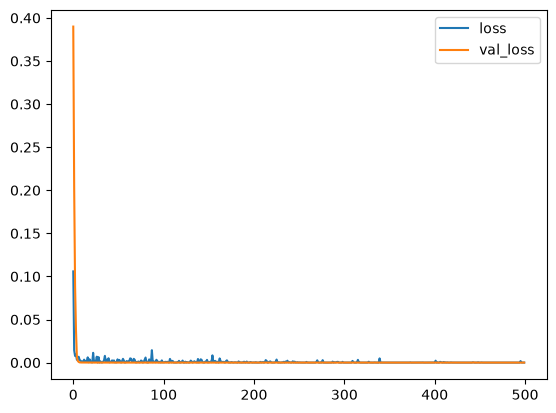

In [22]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

<Axes: >

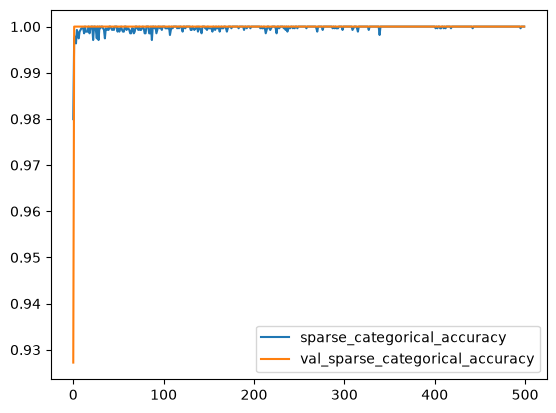

In [23]:
loss_df[['sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()

In [24]:
model = keras.models.load_model("best_model_gold.keras")

In [25]:
# compare the final model loss/accuracy/evaluation values
# the values should again match mostly
print("Test data evaluation:")
print(model.evaluate(x_test, y_test, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(x_train, y_train, verbose=0))

Test data evaluation:
[0.0, 1.0]

Train data evaluation:
[0.0, 1.0]


In [26]:
# get predictions and convert with argmax() to get categories 
# instead of raw probabilities
test_predictions = model.predict(x_test)
test_predictions = np.argmax(test_predictions, axis=1)

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


<Axes: >

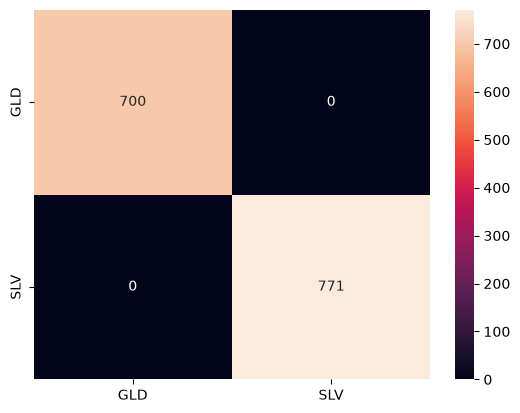

In [27]:
# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(y_test, test_predictions), annot=True, fmt='g', 
            xticklabels=class_names, yticklabels=class_names)

In [28]:
# print the classification report based on true values and predictions
print(classification_report(y_test, test_predictions, target_names=class_names))

# get overall accuracy of the model and print it
acc = accuracy_score(y_test, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

              precision    recall  f1-score   support

         GLD       1.00      1.00      1.00       700
         SLV       1.00      1.00      1.00       771

    accuracy                           1.00      1471
   macro avg       1.00      1.00      1.00      1471
weighted avg       1.00      1.00      1.00      1471


Model overall accuracy: 100.00%


Test the model with some imaginary/synthetic signal examples from your favorite generative AI

In [29]:
# switch to decimal format in NumPy for easier probabilities
np.set_printoptions(suppress=True)

In [30]:
signal_index = 8
print(y_test[signal_index])               # 0 or 1
print(class_names[y_test[signal_index]])  # GLD or SLV

0
GLD


0
GLD


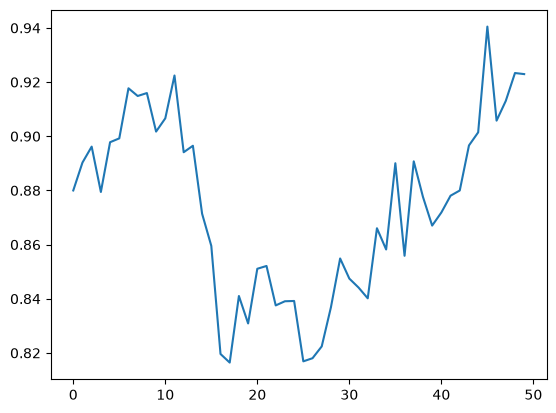

In [31]:

# example signal from test data
# GOLD (GLD)
# (first GLD signal in the test set; change the number to see another one)
signal_index = 8
print(y_test[signal_index])
print(class_names[y_test[signal_index]])

plt.figure()
plt.plot(x_test[signal_index])
plt.show()

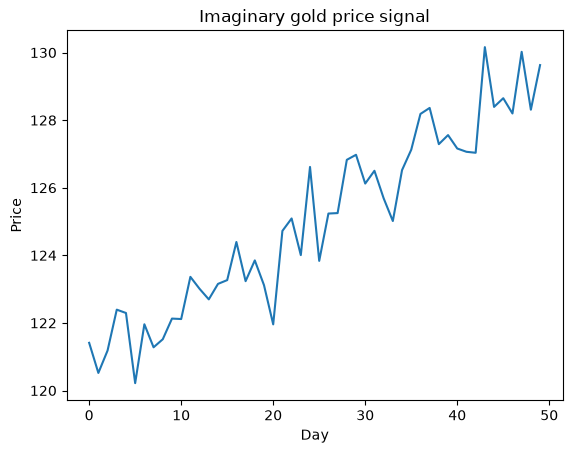

In [32]:
# IMAGINARY GOLD SIGNAL (GLD)
# This code was modified with the help of Claude AI
# (gold is around 120) and scale it with our fitted scaler afterwards,
# so it matches what the model saw during training
import numpy as np
import matplotlib.pyplot as plt

# Create x values from 0 to 49
x = np.arange(50)

# Create y values: slow upward drift around 120 with small daily noise
np.random.seed(0)  # For reproducibility
y = 120 + 0.2 * x + np.random.normal(0, 0.8, size=x.shape)

# Plot the result (optional)
plt.plot(x, y)
plt.xlabel('Day')
plt.ylabel('Price')
plt.title('Imaginary gold price signal')
plt.show()

In [33]:
# TRY OUR IMAGINARY GOLD SIGNAL WITH THE MODEL

# wrap up the data points into the required NumPy-format
points = y
test_signal = np.expand_dims(points, axis=1)
test_batch = np.array([test_signal])

# create prediction
test_predict = model.predict(test_batch)
print(test_predict)

# get highest index and print name
index = np.argmax(test_predict)
print(class_names[index])

# it seems to predict  correctly also from an imaginary signal!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
[[1. 0.]]
GLD


In [34]:
print(np.where(y_test == 1)[0][:5])

[ 1  5  6  9 10]


1
SLV


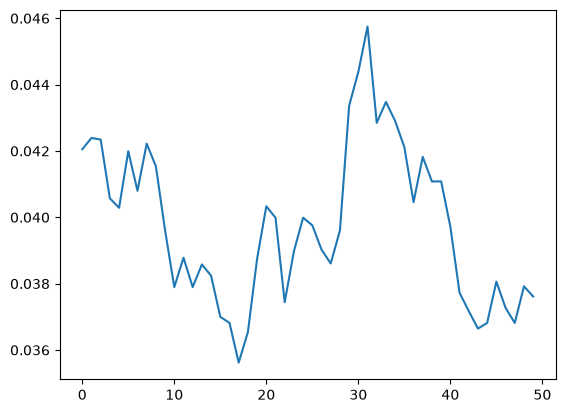

In [35]:
# example signal from test data
# SILVER (SLV)
signal_index = 5
print(y_test[signal_index])
print(class_names[y_test[signal_index]])

plt.figure()
plt.plot(x_test[signal_index])
plt.show()

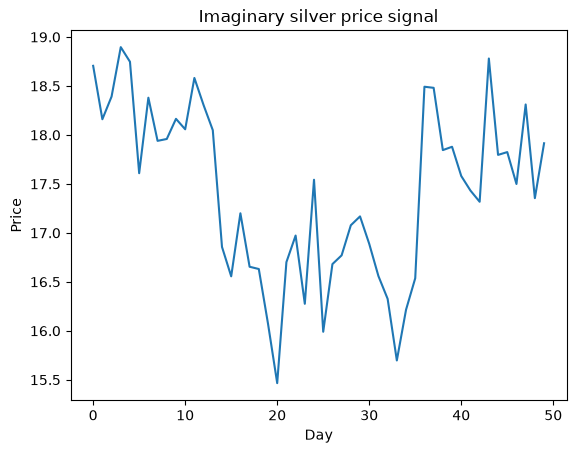

In [36]:
# IMAGINARY SILVER SIGNAL (SLV)
# silver is around 18 and more volatile than gold

import numpy as np
import matplotlib.pyplot as plt

# Create x values from 0 to 49
x = np.arange(50)

# Create y values: around 18 with a dip in the middle (indices 14 to 35)
np.random.seed(0)  # For reproducibility
y = 18 + np.random.normal(0, 0.4, size=x.shape)
y[14:36] -= 1.5 + np.random.normal(0, 0.2, size=22)

# Plot the result (optional)
plt.plot(x, y)
plt.xlabel('Day')
plt.ylabel('Price')
plt.title('Imaginary silver price signal')
plt.show()

In [37]:
# TRY OUR IMAGINARY SILVER SIGNAL WITH THE MODEL
# This was corrected with the help of Claude AI
# scale with the same scaler as the training data
points = scaler.transform(y.reshape(1, -1))[0]
test_signal = np.expand_dims(points, axis=1)
test_batch = np.array([test_signal])

# create prediction
test_predict = model.predict(test_batch)
print(test_predict)

# get highest index and name for this prediction
index = np.argmax(test_predict)
print(class_names[index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
[[0. 1.]]
SLV
